# 📷 Belajar Pengolahan Citra (OpenCV) Praktis
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

Notebook interaktif 50 topik belajar Computer Vision dan Image Processing menggunakan OpenCV & Python. Menggunakan dataset citra nyata (`pohon.jpg`, `wajah.jpg`, `burung.jpg`) dan file video (`video.mp4`).


### Import OpenCV & NumPy


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version : {np.__version__}")


OpenCV version: 4.14.0
NumPy version : 2.2.6


### Helper Fungsi Visualisasi


In [2]:
def tampilkan(citra, judul="", ukuran=(5, 5), cmap=None):
    plt.figure(figsize=ukuran)
    if len(citra.shape) == 3:
        plt.imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(citra, cmap=cmap or 'gray')
    if judul:
        plt.title(judul)
    plt.axis('off')
    plt.show()


### Membaca Gambar (cv2.imread)


In [3]:
# Membaca gambar pohon.jpg
img = cv2.imread("pohon.jpg")
print("Gambar berhasil dimuat. Tipe objek:", type(img))


Gambar berhasil dimuat. Tipe objek: <class 'numpy.ndarray'>


### Menampilkan Gambar (cv2_imshow & Matplotlib)


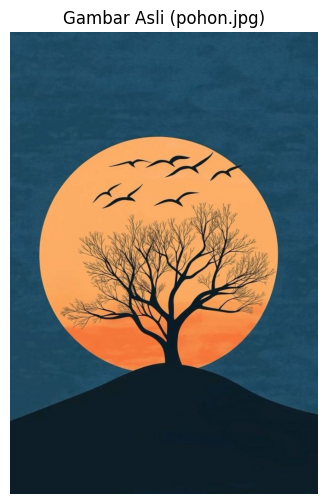

In [4]:
# Di Google Colab gunakan: from google.colab.patches import cv2_imshow; cv2_imshow(img)
# Di notebook umum / Colab dapat menggunakan Matplotlib:
tampilkan(img, "Gambar Asli (pohon.jpg)", ukuran=(6, 6))


### Menyimpan Gambar (cv2.imwrite)


In [5]:
status_simpan = cv2.imwrite("hasil_simpan.png", img)
print("File berhasil disimpan ke hasil_simpan.png:", status_simpan)


File berhasil disimpan ke hasil_simpan.png: True


### Properti Citra (Resolusi & Channel)


In [6]:
tinggi, lebar, channel = img.shape
print(f"Tinggi (tinggi piksel) : {tinggi} px")
print(f"Lebar (lebar piksel)   : {lebar} px")
print(f"Jumlah channel warna   : {channel} (BGR)")
print(f"Tipe data array        : {img.dtype}")


Tinggi (tinggi piksel) : 1024 px
Lebar (lebar piksel)   : 682 px
Jumlah channel warna   : 3 (BGR)
Tipe data array        : uint8


### Akses Nilai Piksel BGR


In [7]:
# Mengambil nilai piksel pada koordinat y=200, x=200
b, g, r = img[200, 200]
print(f"Piksel pada koordinat (200, 200) -> Blue: {b}, Green: {g}, Red: {r}")


Piksel pada koordinat (200, 200) -> Blue: 96, Green: 75, Red: 30


### Modifikasi Piksel Manual


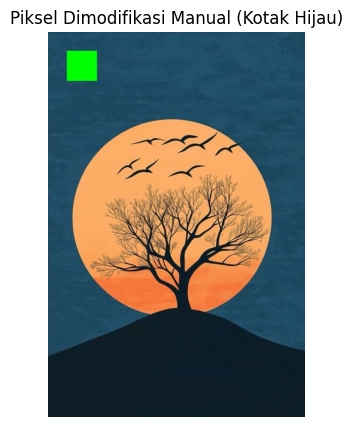

In [8]:
img_mod = img.copy()
# Mengubah area kotak 80x80 di pojok kiri atas menjadi warna hijau terang
img_mod[50:130, 50:130] = [0, 255, 0]
tampilkan(img_mod, "Piksel Dimodifikasi Manual (Kotak Hijau)")


### Membuat Kanvas Kosong


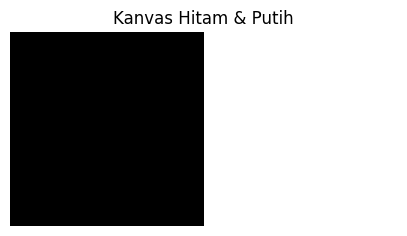

In [9]:
# Kanvas hitam dan putih
kanvas_hitam = np.zeros((200, 200, 3), dtype=np.uint8)
kanvas_putih = np.full((200, 200, 3), 255, dtype=np.uint8)

tampilkan(np.hstack([kanvas_hitam, kanvas_putih]), "Kanvas Hitam & Putih")


### Mengubah Ukuran Gambar (Resize)


Dimensi setelah resize: (300, 300, 3)


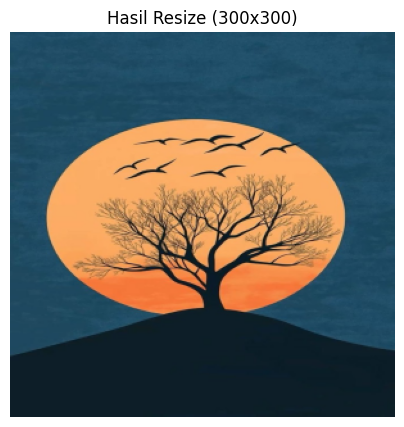

In [10]:
# Resize ke resolusi 300x300
img_resized = cv2.resize(img, (300, 300), interpolation=cv2.INTER_AREA)
print(f"Dimensi setelah resize: {img_resized.shape}")
tampilkan(img_resized, "Hasil Resize (300x300)")


### Memotong Gambar (Cropping)


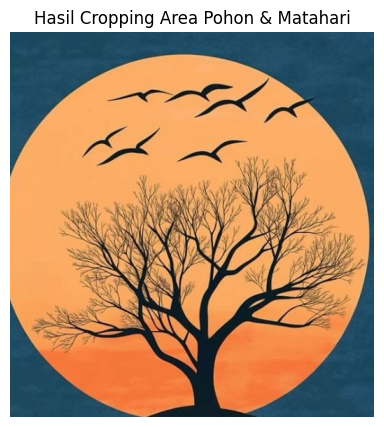

In [11]:
# Crop fokus ke siluet pohon dan matahari [y1:y2, x1:x2]
crop = img[200:750, 80:600]
tampilkan(crop, "Hasil Cropping Area Pohon & Matahari")


### Translasi Gambar


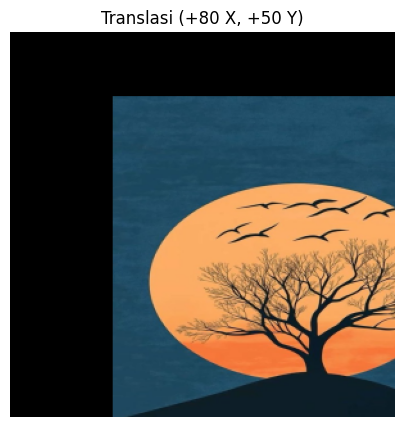

In [12]:
# Geser X +80px, Y +50px
M_translasi = np.float32([[1, 0, 80], [0, 1, 50]])
img_geser = cv2.warpAffine(img_resized, M_translasi, (300, 300))
tampilkan(img_geser, "Translasi (+80 X, +50 Y)")


### Rotasi Gambar


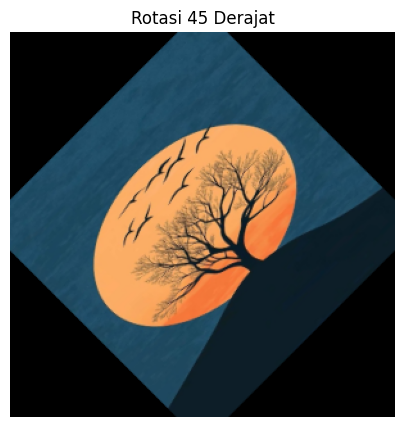

In [13]:
pusat = (150, 150)
M_rotasi = cv2.getRotationMatrix2D(pusat, angle=45, scale=0.8)
img_putar = cv2.warpAffine(img_resized, M_rotasi, (300, 300))
tampilkan(img_putar, "Rotasi 45 Derajat")


### Membalik Gambar (Flipping)


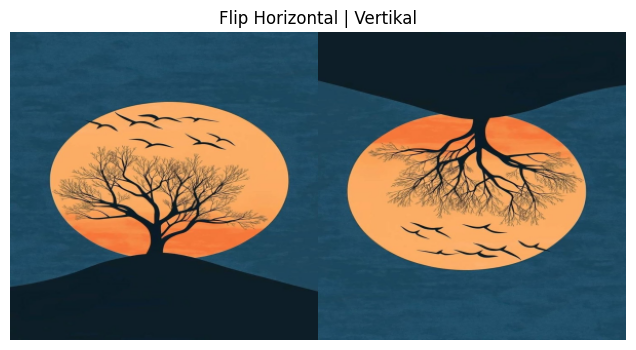

In [14]:
flip_h = cv2.flip(img_resized, 1) # Horizontal
flip_v = cv2.flip(img_resized, 0) # Vertikal
tampilkan(np.hstack([flip_h, flip_v]), "Flip Horizontal | Vertikal", ukuran=(8, 4))


### Menggambar Garis


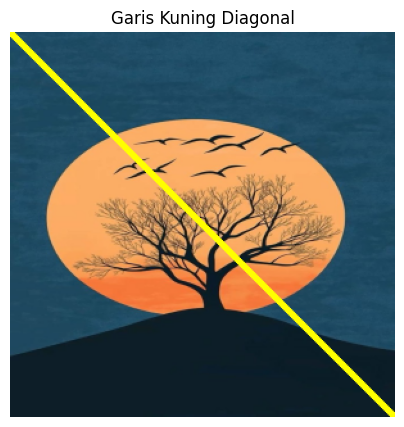

In [15]:
kanvas_garis = img_resized.copy()
cv2.line(kanvas_garis, (0, 0), (300, 300), (0, 255, 255), thickness=4)
tampilkan(kanvas_garis, "Garis Kuning Diagonal")


### Menggambar Persegi dan Lingkaran


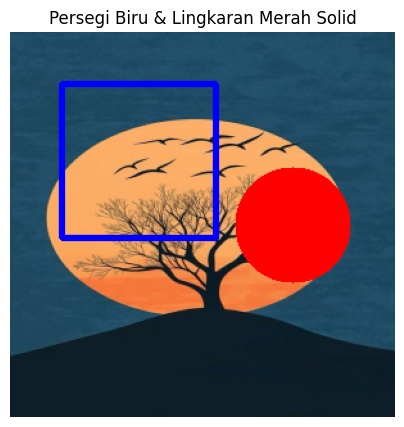

In [16]:
kanvas_bentuk = img_resized.copy()
cv2.rectangle(kanvas_bentuk, (40, 40), (160, 160), (255, 0, 0), thickness=3)
cv2.circle(kanvas_bentuk, (220, 150), 45, (0, 0, 255), thickness=-1)
tampilkan(kanvas_bentuk, "Persegi Biru & Lingkaran Merah Solid")


### Menambahkan Teks pada Gambar


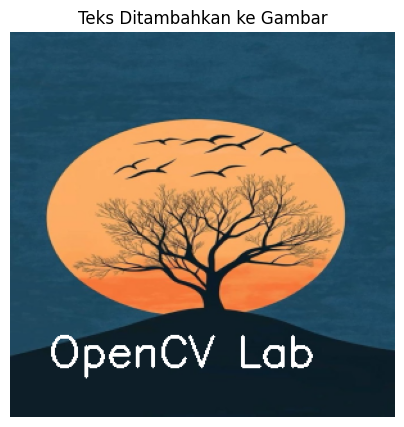

In [17]:
kanvas_teks = img_resized.copy()
cv2.putText(kanvas_teks, "OpenCV Lab", (30, 260), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 2)
tampilkan(kanvas_teks, "Teks Ditambahkan ke Gambar")


### Konversi BGR ke Grayscale


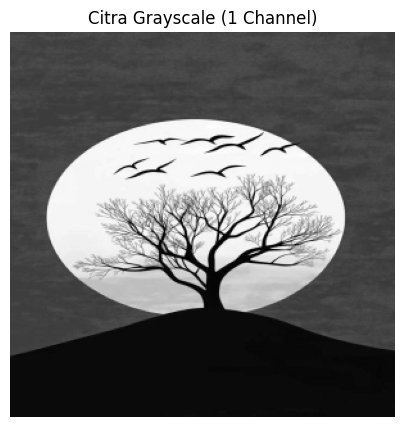

In [18]:
gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
tampilkan(gray, "Citra Grayscale (1 Channel)")


### Konversi ke Ruang Warna HSV


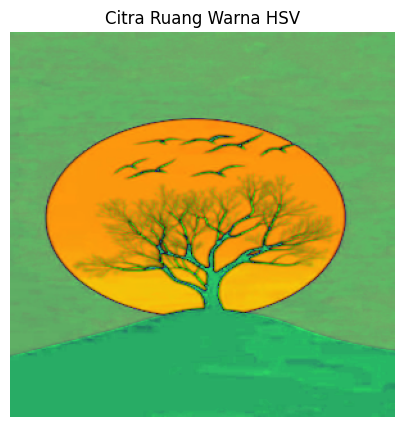

In [19]:
hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
tampilkan(hsv, "Citra Ruang Warna HSV")


### Memisahkan Channel Warna (Split)


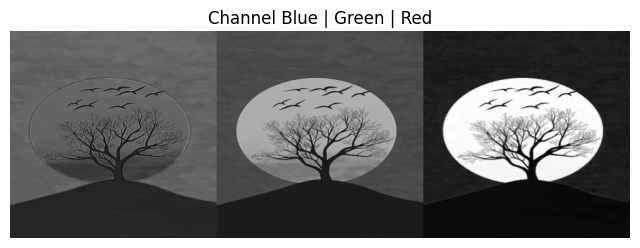

In [20]:
b_ch, g_ch, r_ch = cv2.split(img_resized)
tampilkan(np.hstack([b_ch, g_ch, r_ch]), "Channel Blue | Green | Red", ukuran=(8, 3))


### Menggabungkan Channel Warna (Merge)


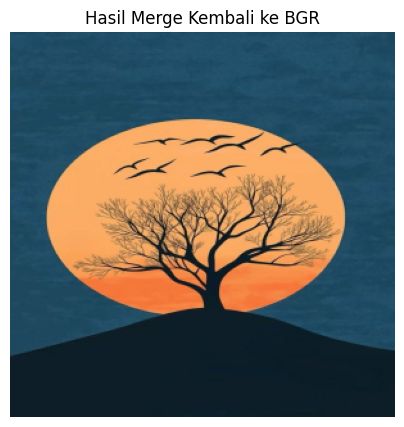

In [21]:
merged = cv2.merge([b_ch, g_ch, r_ch])
tampilkan(merged, "Hasil Merge Kembali ke BGR")


### Simple Thresholding


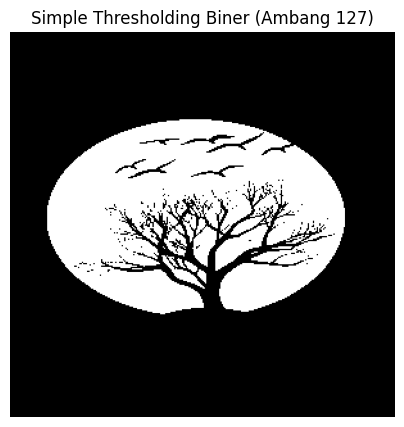

In [22]:
ret, thresh_simple = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
tampilkan(thresh_simple, "Simple Thresholding Biner (Ambang 127)")


### Adaptive Thresholding


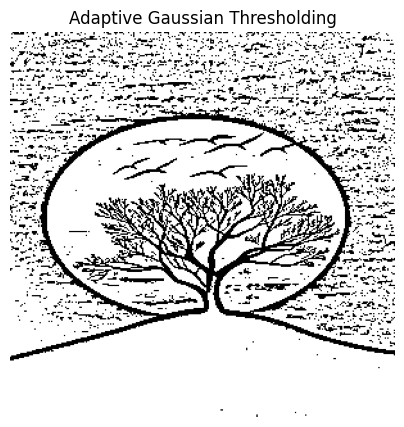

In [23]:
thresh_adaptif = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
)
tampilkan(thresh_adaptif, "Adaptive Gaussian Thresholding")


### Otsu's Thresholding


Ambang batas optimal Otsu: 112.0


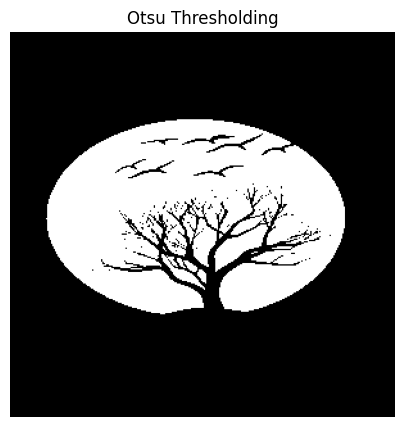

In [24]:
ret_otsu, thresh_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Ambang batas optimal Otsu: {ret_otsu:.1f}")
tampilkan(thresh_otsu, "Otsu Thresholding")


### Membalik Warna Citra (Invert)


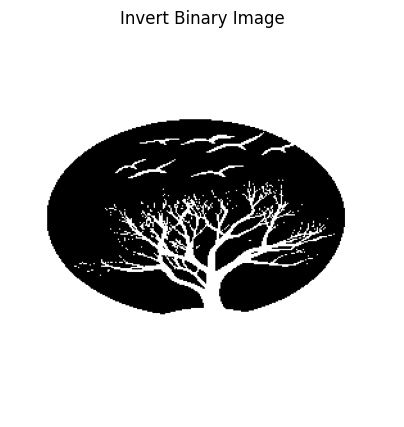

In [25]:
invert_img = cv2.bitwise_not(thresh_simple)
tampilkan(invert_img, "Invert Binary Image")


### Custom Filter dan Konvolusi 2D


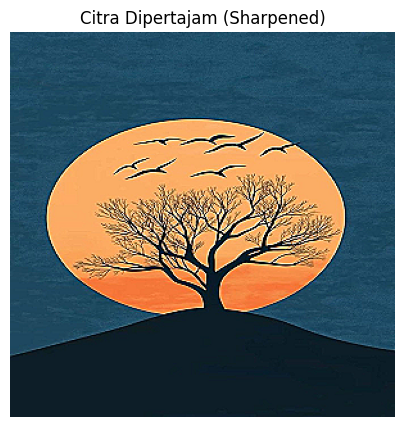

In [26]:
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])
tajam = cv2.filter2D(img_resized, -1, kernel_sharpen)
tampilkan(tajam, "Citra Dipertajam (Sharpened)")


### Averaging Blur


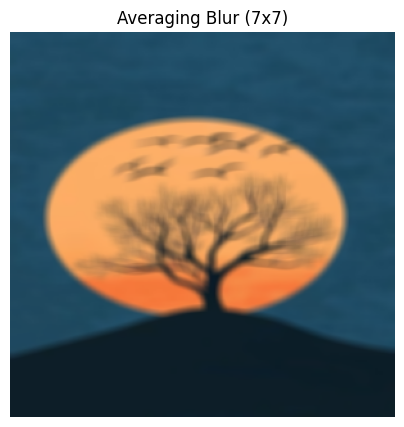

In [27]:
blur_rata = cv2.blur(img_resized, (7, 7))
tampilkan(blur_rata, "Averaging Blur (7x7)")


### Gaussian Blur


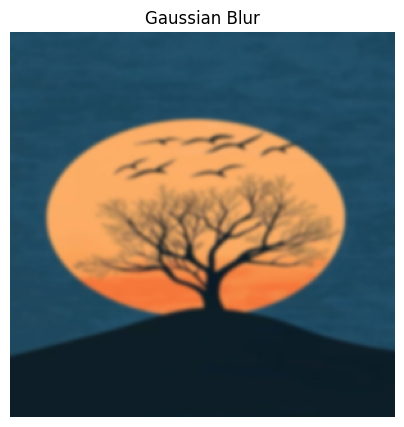

In [28]:
blur_gaussian = cv2.GaussianBlur(img_resized, (7, 7), sigmaX=0)
tampilkan(blur_gaussian, "Gaussian Blur")


### Median Blur


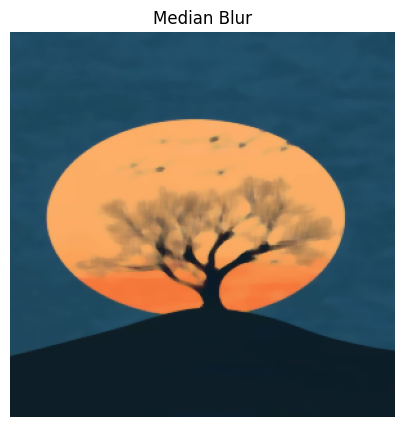

In [29]:
blur_median = cv2.medianBlur(img_resized, 7)
tampilkan(blur_median, "Median Blur")


### Bilateral Filter


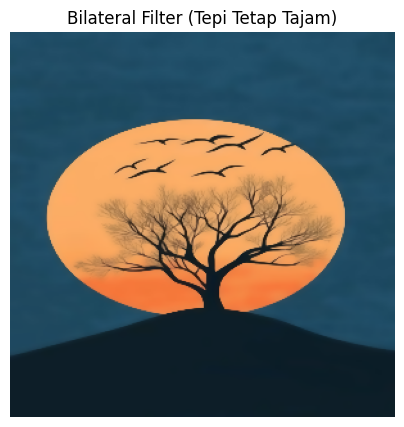

In [30]:
bilateral = cv2.bilateralFilter(img_resized, d=9, sigmaColor=75, sigmaSpace=75)
tampilkan(bilateral, "Bilateral Filter (Tepi Tetap Tajam)")


### Deteksi Tepi Sobel


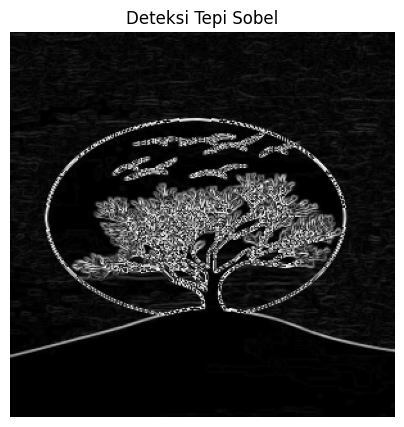

In [31]:
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_gabung = cv2.magnitude(sobelx, sobely)

tampilkan(np.uint8(np.absolute(sobel_gabung)), "Deteksi Tepi Sobel")


### Deteksi Tepi Laplacian


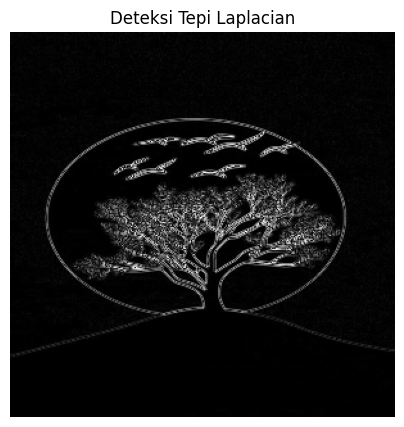

In [32]:
laplacian = cv2.Laplacian(gray, cv2.CV_64F)
tampilkan(np.uint8(np.absolute(laplacian)), "Deteksi Tepi Laplacian")


### Canny Edge Detection


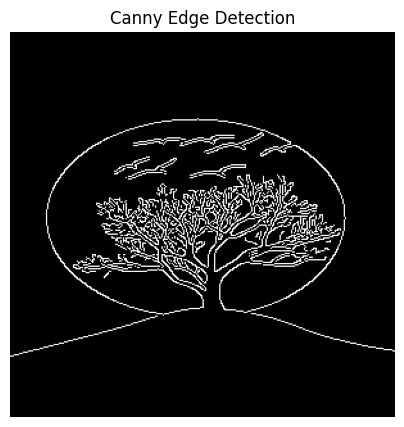

In [33]:
edges = cv2.Canny(gray, threshold1=100, threshold2=200)
tampilkan(edges, "Canny Edge Detection")


### Operasi Morfologi Erosi


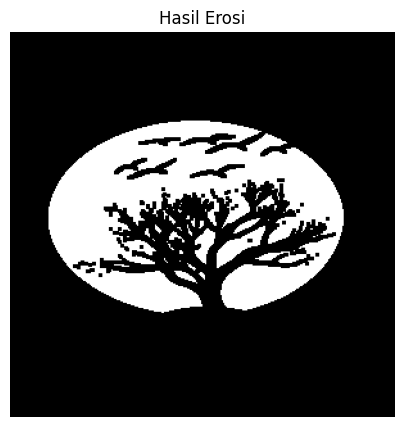

In [34]:
kernel_morf = np.ones((3, 3), np.uint8)
erosi = cv2.erode(thresh_simple, kernel_morf, iterations=1)
tampilkan(erosi, "Hasil Erosi")


### Operasi Morfologi Dilasi


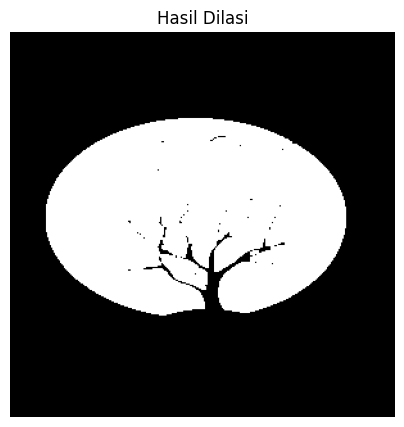

In [35]:
dilasi = cv2.dilate(thresh_simple, kernel_morf, iterations=1)
tampilkan(dilasi, "Hasil Dilasi")


### Morfologi Opening


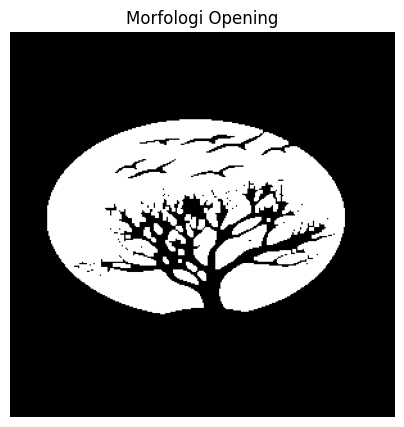

In [36]:
opening = cv2.morphologyEx(thresh_simple, cv2.MORPH_OPEN, kernel_morf)
tampilkan(opening, "Morfologi Opening")


### Morfologi Closing


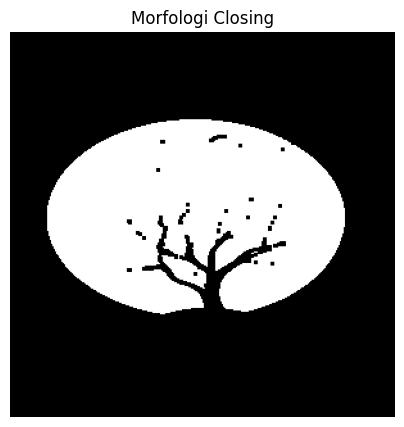

In [37]:
closing = cv2.morphologyEx(thresh_simple, cv2.MORPH_CLOSE, kernel_morf)
tampilkan(closing, "Morfologi Closing")


### Deteksi Kontur (findContours)


In [38]:
contours, hierarchy = cv2.findContours(thresh_simple, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
print(f"Jumlah kontur terdeteksi: {len(contours)}")


Jumlah kontur terdeteksi: 271


### Menggambar Kontur (drawContours)


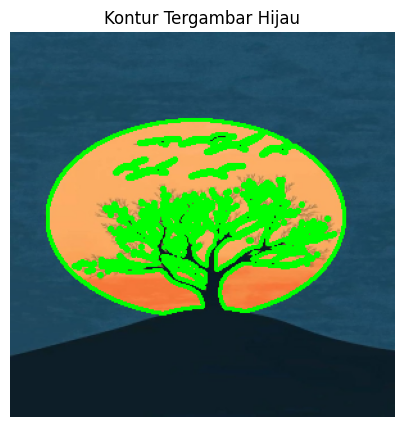

In [39]:
img_kontur = img_resized.copy()
cv2.drawContours(img_kontur, contours, -1, (0, 255, 0), thickness=2)
tampilkan(img_kontur, "Kontur Tergambar Hijau")


### Bounding Box pada Objek


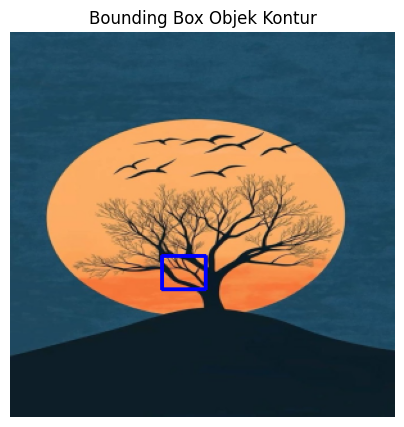

In [40]:
img_bbox = img_resized.copy()
for cnt in contours[:10]:
    x, y, w, h = cv2.boundingRect(cnt)
    if w > 20 and h > 20:
        cv2.rectangle(img_bbox, (x, y), (x + w, y + h), (255, 0, 0), 2)
tampilkan(img_bbox, "Bounding Box Objek Kontur")


### Menghitung Luas Area dan Keliling Kontur


In [41]:
for idx, cnt in enumerate(contours[:5]):
    luas = cv2.contourArea(cnt)
    keliling = cv2.arcLength(cnt, closed=True)
    print(f"Kontur #{idx+1} -> Luas: {luas:.1f} px^2 | Keliling: {keliling:.1f} px")


Kontur #1 -> Luas: 35.0 px^2 | Keliling: 26.1 px
Kontur #2 -> Luas: 0.0 px^2 | Keliling: 14.0 px
Kontur #3 -> Luas: 35.5 px^2 | Keliling: 27.6 px
Kontur #4 -> Luas: 12.5 px^2 | Keliling: 20.7 px
Kontur #5 -> Luas: 181.5 px^2 | Keliling: 104.5 px


### Operasi Bitwise (AND, OR, XOR)


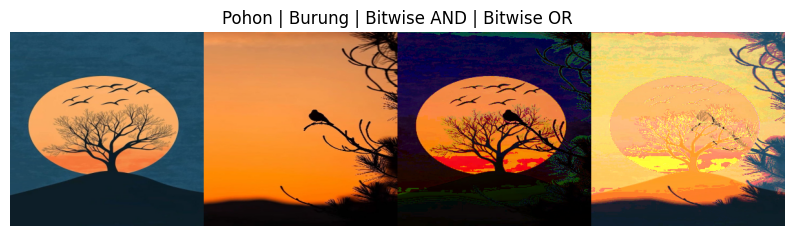

In [42]:
# Menggunakan dua gambar: pohon.jpg dan burung.jpg
img_burung = cv2.resize(cv2.imread("burung.jpg"), (300, 300))

bit_and = cv2.bitwise_and(img_resized, img_burung)
bit_or = cv2.bitwise_or(img_resized, img_burung)
tampilkan(np.hstack([img_resized, img_burung, bit_and, bit_or]), "Pohon | Burung | Bitwise AND | Bitwise OR", ukuran=(10, 3))


### Image Masking


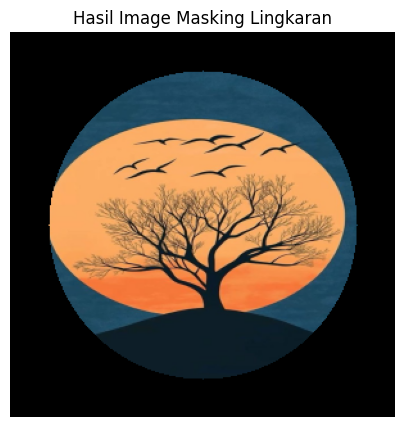

In [43]:
mask = np.zeros((300, 300), dtype=np.uint8)
cv2.circle(mask, (150, 150), 120, 255, -1)
img_masked = cv2.bitwise_and(img_resized, img_resized, mask=mask)
tampilkan(img_masked, "Hasil Image Masking Lingkaran")


### Kalkulasi Histogram Warna


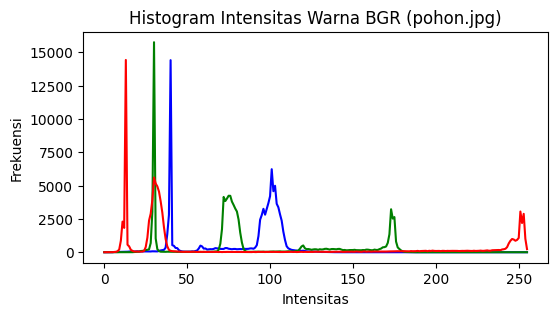

In [44]:
plt.figure(figsize=(6, 3))
warna = ('b', 'g', 'r')
for i, col in enumerate(warna):
    hist = cv2.calcHist([img_resized], [i], None, [256], [0, 256])
    plt.plot(hist, color=col)
plt.title("Histogram Intensitas Warna BGR (pohon.jpg)")
plt.xlabel("Intensitas")
plt.ylabel("Frekuensi")
plt.show()


### Histogram Equalization


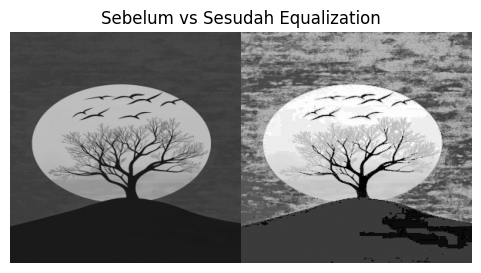

In [45]:
equ = cv2.equalizeHist(gray)
tampilkan(np.hstack([gray, equ]), "Sebelum vs Sesudah Equalization", ukuran=(6, 3))


### CLAHE (Adaptive Histogram Equalization)


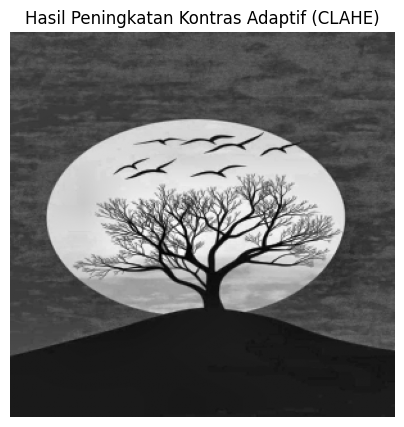

In [46]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
cl_img = clahe.apply(gray)
tampilkan(cl_img, "Hasil Peningkatan Kontras Adaptif (CLAHE)")


### Template Matching


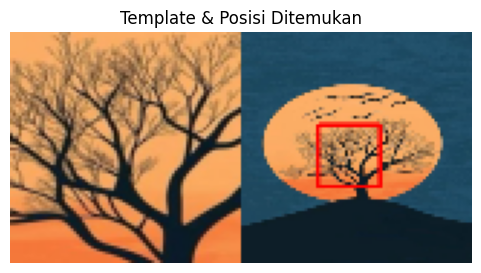

In [47]:
template = img_resized[120:200, 100:180]
res = cv2.matchTemplate(img_resized, template, cv2.TM_CCOEFF_NORMED)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

img_match = img_resized.copy()
h_t, w_t = template.shape[:2]
cv2.rectangle(img_match, max_loc, (max_loc[0] + w_t, max_loc[1] + h_t), (0, 0, 255), 3)

tampilkan(np.hstack([cv2.resize(template, (w_t, h_t)), cv2.resize(img_match, (w_t, h_t))]), "Template & Posisi Ditemukan", ukuran=(6, 3))


### Deteksi Wajah dengan Haar Cascades


Jumlah wajah terdeteksi pada wajah.jpg: 1


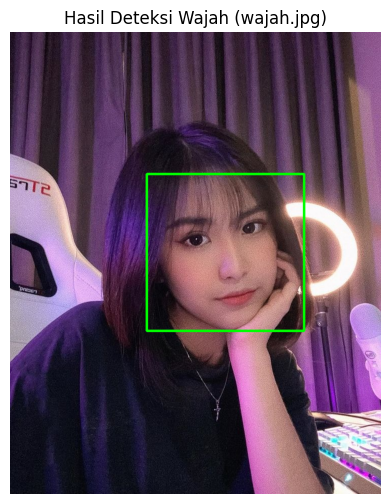

In [48]:
# Membaca gambar kedua (wajah.jpg) untuk deteksi wajah
img_wajah = cv2.imread("wajah.jpg")
gray_wajah = cv2.cvtColor(img_wajah, cv2.COLOR_BGR2GRAY)

cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(cascade_path)

faces = face_cascade.detectMultiScale(gray_wajah, scaleFactor=1.1, minNeighbors=4)
img_hasil_wajah = img_wajah.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(img_hasil_wajah, (x, y), (x + w, y + h), (0, 255, 0), 4)

print(f"Jumlah wajah terdeteksi pada wajah.jpg: {len(faces)}")
tampilkan(img_hasil_wajah, "Hasil Deteksi Wajah (wajah.jpg)", ukuran=(6, 6))


### Membaca File Video


In [49]:
# Memuat file video.mp4
cap = cv2.VideoCapture("video.mp4")
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
lebar_v = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
tinggi_v = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"File video.mp4 berhasil dimuat:")
print(f"- Total frame: {total_frames}")
print(f"- FPS        : {fps}")
print(f"- Resolusi   : {lebar_v}x{tinggi_v}")


File video.mp4 berhasil dimuat:
- Total frame: 300
- FPS        : 25.0
- Resolusi   : 368x368


### Ekstraksi Frame dari Video


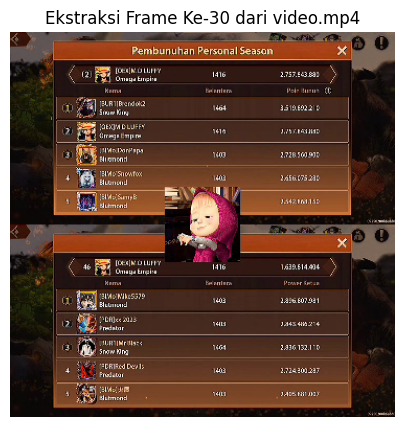

In [50]:
# Mengambil frame ke-30 dari video.mp4
cap.set(cv2.CAP_PROP_POS_FRAMES, 30)
ret, frame_30 = cap.read()
if ret:
    cv2.imwrite("hasil_frame_30.jpg", frame_30)
    tampilkan(frame_30, "Ekstraksi Frame Ke-30 dari video.mp4")
cap.release()


### Membuat dan Menyimpan File Video (VideoWriter)


In [51]:
# Membaca video.mp4, menerapkan efek deteksi tepi Canny, dan menyimpannya ke hasil_video.mp4
cap = cv2.VideoCapture("video.mp4")
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter("hasil_video.mp4", fourcc, 25.0, (lebar_v, tinggi_v))

count = 0
while cap.isOpened() and count < 30:
    ret, frame = cap.read()
    if not ret:
        break
    edges = cv2.Canny(frame, 100, 200)
    edges_bgr = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
    out.write(edges_bgr)
    count += 1

cap.release()
out.release()
print(f"Pemrosesan selesai. {count} frame berhasil disimpan ke hasil_video.mp4")


Pemrosesan selesai. 30 frame berhasil disimpan ke hasil_video.mp4
